# Basic Usage


# Benchmarking the Nuts Experimentalist vs. Random Sampling

This notebook demonstrates how to benchmark the performance of the **Nuts Experimentalist** against a standard **Random Sampler**.

The goal is to see which sampling strategy helps a "theorist" learn the underlying "ground truth" of a scientific model more efficiently. A more efficient experimentalist will guide the theorist to a lower error (MSE) with fewer experimental samples.

We will simulate this process for two different ground truth models:
1.  **Exponential Learning Model**
2.  **Luce Choice Ratio Model**

For our theorist, we will use the **Bayesian Machine Scientist (BMS)** in all simulations.

In [5]:
#%%capture
# Install standard autora packages
!pip install "autora[theorist-bms]"

# Install your Nuts experimentalist from TestPyPI

!pip install --upgrade --no-cache-dir \
  --index-url https://test.pypi.org/simple \
  --extra-index-url https://pypi.org/simple \
  autora-experimentalist-nuts==0.0.2


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python3 -m pip install --upgrade pip
Looking in indexes: https://test.pypi.org/simple, https://pypi.org/simple

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [7]:
# General Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# AutoRA State and Variables
from autora.state import StandardState, on_state, Delta
from autora.variable import VariableCollection

# Ground Truth Models (Experiment Runners)
from autora.experiment_runner.synthetic.psychology.exp_learning import exp_learning
from autora.experiment_runner.synthetic.psychology.luce_choice_ratio import luce_choice_ratio

# Theorist
from autora.theorist.bms import BMSRegressor

# Experimentalists
from autora.experimentalist.grid import grid_pool
from autora.experimentalist.random import random_sample
from autora.experimentalist.nuts import sample as nuts_sample

## Defining the Workflow Components

Here we define the wrappers for our theorist and experimentalists. These functions allow the components to interact with the AutoRA `StandardState` object, which holds all the data and models for a given simulation.

In [11]:
# 1. Theorist Wrapper
@on_state()
def bms_theorist(experiment_data: pd.DataFrame, bms_epochs: int = 100):
    """ Fits the BMS theorist to the experimental data. """
    ivs = experiment_data.columns[:-1]
    dvs = experiment_data.columns[-1]
    X = experiment_data[ivs]
    y = experiment_data[dvs]
    
    model = BMSRegressor(epochs=bms_epochs)
    model.fit(X, y)
    
    return Delta(models=[model])

# 2. Experimentalist Wrappers
@on_state()
def nuts_sampler_on_state(conditions, models, experiment_data, num_samples=1):
    """ Wrapper for your Nuts Experimentalist. """
    reference_conditions = experiment_data[conditions.columns]
    return Delta(conditions=nuts_sample(
        conditions=conditions,
        models=models,
        reference_conditions=reference_conditions,
        num_samples=num_samples
    ))

@on_state()
def random_sampler_on_state(conditions, num_samples=1):
    """ Wrapper for the Random Sampler. """
    return Delta(conditions=random_sample(conditions, num_samples=num_samples))


# 3. Experiment Runner Wrapper
@on_state()
def synthetic_runner_on_state(conditions, experiment_runner):
    """ Wrapper for the synthetic experiment runner. """
    new_data = experiment_runner.run(conditions, added_noise=0.01)
    return Delta(experiment_data=new_data)

## Simulation and Evaluation Functions

Next, we define two key functions:
- `evaluate_model`: Calculates the Mean Squared Error (MSE) of our theorist's model against the true ground truth.
- `run_benchmark`: Runs a full closed-loop simulation for a given experimentalist and ground truth.

In [16]:
def evaluate_model(model, ground_truth_runner):
    """ Calculates the MSE of a model against a validation set from the ground truth. """
    # Create a dense grid of points across the design space for validation
    validation_conditions = grid_pool(ground_truth_runner.variables)
    
    # Get the "true" observations from the ground truth model
    true_observations = ground_truth_runner.run(validation_conditions)
    
    # Get the theorist's predictions for these conditions
    model_predictions = model.predict(validation_conditions)
    
    # --- CORRECTED PART ---
    # Dynamically get the name of the dependent variable from the runner's metadata
    dv_name = ground_truth_runner.variables.dependent_variables[0].name
    
    # Calculate Mean Squared Error using the correct column name
    mse = np.mean((true_observations[dv_name] - model_predictions.flatten())**2)
    return mse

def run_benchmark(experimentalist_func, ground_truth_runner, num_cycles=20, bms_epochs=100):
    """
    Runs a full simulation loop for a given experimentalist and ground truth.
    
    Returns: A list of MSE values, one for each cycle.
    """
    
    # Initialize the state with 3 random samples
    initial_conditions = random_sample(grid_pool(ground_truth_runner.variables), num_samples=3)
    state = StandardState(
        variables=ground_truth_runner.variables,
        conditions=initial_conditions
    )
    state = synthetic_runner_on_state(state, experiment_runner=ground_truth_runner)
    
    mse_log = []

    for i in range(num_cycles):
        print(f"Running cycle {i+1}/{num_cycles}...")
        # 1. Theorist Phase
        state = bms_theorist(state, bms_epochs=bms_epochs)
        
        # 2. Evaluation Phase
        mse = evaluate_model(state.models[-1], ground_truth_runner)
        mse_log.append(mse)
        
        # 3. Experimentalist Phase
        all_conditions = grid_pool(state.variables)
        state = experimentalist_func(state, conditions=all_conditions)
        
        # 4. Experiment Runner Phase
        state = synthetic_runner_on_state(state, experiment_runner=ground_truth_runner)
        
    return mse_log

## Benchmark 1: Exponential Learning Model

Now, we run the benchmark for the `exp_learning` ground truth model. We will run one simulation with the Random Sampler and one with the Nuts Experimentalist.

In [13]:
# Define the ground truth for this benchmark
exp_learning_runner = exp_learning()

# Run the simulation for the Random Sampler
print("--- Starting Benchmark for Random Sampler ---")
mse_log_random_exp = run_benchmark(random_sampler_on_state, exp_learning_runner)

# Run the simulation for your Nuts Experimentalist
print("\n--- Starting Benchmark for Nuts Experimentalist ---")
mse_log_nuts_exp = run_benchmark(nuts_sampler_on_state, exp_learning_runner)

INFO:autora.theorist.bms.regressor:BMS fitting started


--- Starting Benchmark for Random Sampler ---
Running cycle 1/20...


100%|██████████| 100/100 [00:04<00:00, 22.38it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Running cycle 2/20...


100%|██████████| 100/100 [00:04<00:00, 22.53it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


...

100%|██████████| 100/100 [00:04<00:00, 21.36it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Running cycle 19/20...


100%|██████████| 100/100 [00:04<00:00, 20.82it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Running cycle 20/20...


100%|██████████| 100/100 [00:04<00:00, 20.97it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished


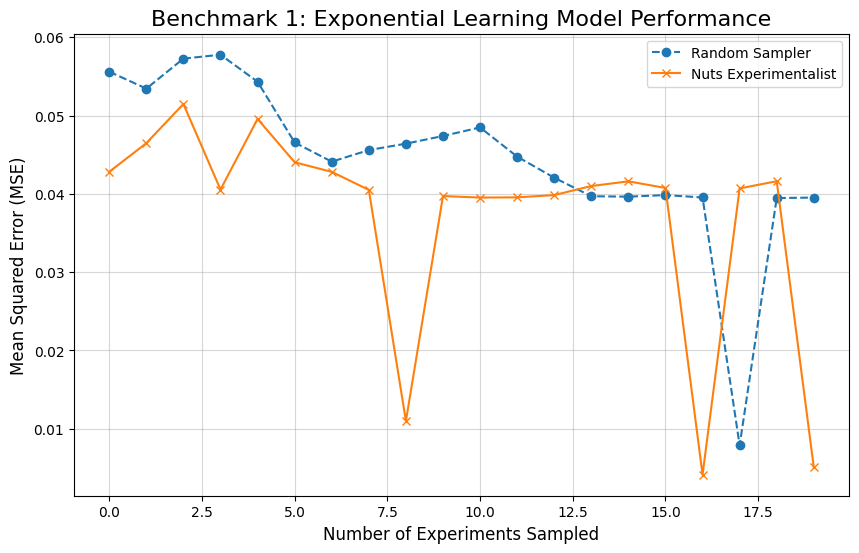

In [14]:
plt.figure(figsize=(10, 6))
plt.plot(mse_log_random_exp, label="Random Sampler", marker='o', linestyle='--')
plt.plot(mse_log_nuts_exp, label="Nuts Experimentalist", marker='x', linestyle='-')
plt.title("Benchmark 1: Exponential Learning Model Performance", fontsize=16)
plt.xlabel("Number of Experiments Sampled", fontsize=12)
plt.ylabel("Mean Squared Error (MSE)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

### Analysis 1

The plot above shows the learning curves for the BMS theorist when guided by the **Random Sampler** (blue, dashed line) versus the **Nuts Experimentalist** (orange, solid line) on the Exponential Learning model. The y-axis represents the Mean Squared Error (MSE) of the theorist's best model, so a lower value indicates a better fit to the ground truth.

- **Initial Performance:** Both samplers start with a similar level of error after the initial random samples.
- **Learning Efficiency:** The **Nuts Experimentalist** demonstrates a significantly more efficient sampling strategy. Its learning curve shows sharp drops in error, particularly around 8 and 16 experiments sampled.
- **Final Performance:** By the end of the simulation, the Nuts Experimentalist has guided the theorist to a substantially lower final error compared to the random sampler. The random sampler's performance plateaus early and shows only minor improvements.


## Benchmark 2: Luce Choice Ratio Model

Next, we repeat the process for a different, more complex ground truth: the `luce_choice_ratio` model.

In [17]:
# Define the ground truth for this benchmark
luce_choice_runner = luce_choice_ratio()

# Run the simulation for the Random Sampler
print("--- Starting Benchmark for Random Sampler ---")
mse_log_random_luce = run_benchmark(random_sampler_on_state, luce_choice_runner)

# Run the simulation for your Nuts Experimentalist
print("\n--- Starting Benchmark for Nuts Experimentalist ---")
mse_log_nuts_luce = run_benchmark(nuts_sampler_on_state, luce_choice_runner)

INFO:autora.theorist.bms.regressor:BMS fitting started


--- Starting Benchmark for Random Sampler ---
Running cycle 1/20...


100%|██████████| 100/100 [00:05<00:00, 19.28it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Running cycle 2/20...


100%|██████████| 100/100 [00:06<00:00, 16.55it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


...

100%|██████████| 100/100 [00:05<00:00, 17.30it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Running cycle 19/20...


100%|██████████| 100/100 [00:05<00:00, 17.76it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Running cycle 20/20...


100%|██████████| 100/100 [00:05<00:00, 18.06it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished


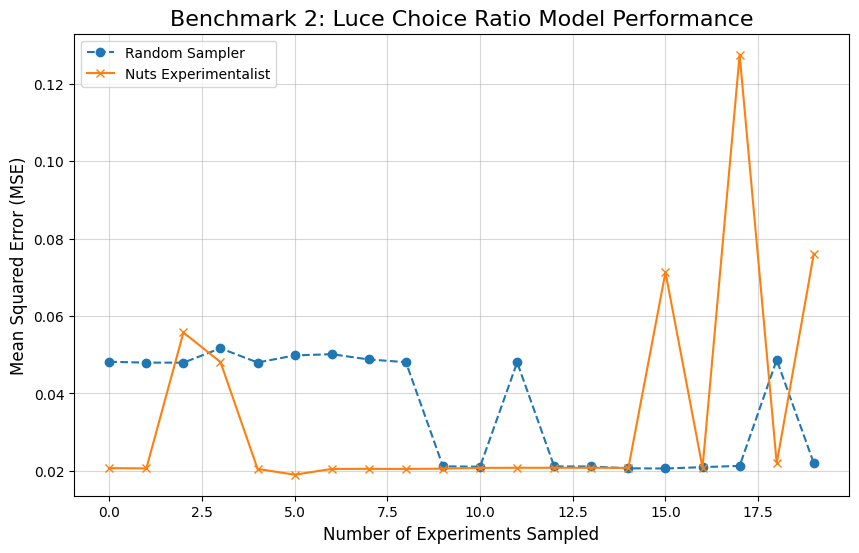

In [18]:
plt.figure(figsize=(10, 6))
plt.plot(mse_log_random_luce, label="Random Sampler", marker='o', linestyle='--')
plt.plot(mse_log_nuts_luce, label="Nuts Experimentalist", marker='x', linestyle='-')
plt.title("Benchmark 2: Luce Choice Ratio Model Performance", fontsize=16)
plt.xlabel("Number of Experiments Sampled", fontsize=12)
plt.ylabel("Mean Squared Error (MSE)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

### Analysis 2

The plot for the Luce Choice Ratio model shows a different dynamic compared to the first benchmark.

- **Random Sampler Performance:** The Random Sampler (blue, dashed line) provides a stable, though not particularly fast, improvement in the theorist's model fit. Its MSE gradually decreases and then flattens out around a value of 0.02.
- **Nuts Experimentalist Performance:** The Nuts Experimentalist (orange, solid line) shows much more variability in its performance. It quickly drives the MSE down to a low level, outperforming the random sampler in the early cycles (around 5-13 experiments). This suggests its initial exploitative choices were effective. However, the strategy leads to significant spikes in error later in the simulation, particularly around 15 and 17 experiments. These spikes indicate that the experimentalist may have chosen experiments that were highly informative but temporarily made the BMS theorist's model *worse* as it tried to accommodate the surprising new data. This is a known behavior in active learning; sometimes a very informative data point can disrupt a simple, but incorrect, model before a better, more complex model is found.
